In [1]:
import json
import pandas as pd

from pathlib import Path
from collections import defaultdict

In [18]:
INPUT_FILE = "G:\\SEVA_Ai\\SEVA_Ai\\notebooks\\data\\analysis\\all_schemes.json"
OUTPUT_DIR = "G:\\SEVA_Ai\\SEVA_Ai\\notebooks\\output"
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Input file:", INPUT_FILE)
print("Output directory:", OUTPUT_DIR)

Input file: G:\SEVA_Ai\SEVA_Ai\notebooks\data\analysis\all_schemes.json
Output directory: G:\SEVA_Ai\SEVA_Ai\notebooks\output


In [19]:

with open(INPUT_FILE, "r", encoding="utf-8") as file:
    schemes = json.load(file)

# Support both JSON formats:
# 1. List of scheme objects
# 2. Single scheme object

if isinstance(schemes, dict):
    schemes = [schemes]

print("Total scheme records:", len(schemes))

Total scheme records: 4428


In [20]:
sample_scheme = schemes[0]

print(json.dumps(
    sample_scheme,
    indent=4,
    ensure_ascii=False
))

{
    "scheme_id": "LBezF5gB5uF80_MGGY81",
    "internal_id": "628727c27d5de378dc7acfe9",
    "slug": "sui",
    "name": "Stand-Up India",
    "short_title": "SUPI",
    "level": "Central",
    "ministry": "Ministry Of Finance",
    "nodal_department": "Department of Financial Service",
    "department": "Banks",
    "states": [
        "All"
    ],
    "categories": [
        "Business & Entrepreneurship",
        "Banking,Financial Services and Insurance",
        "Social welfare & Empowerment"
    ],
    "tags": [
        "Loan",
        "Entrepreneur",
        "Finance",
        "Business"
    ],
    "target_beneficiaries": [
        {
            "value": "individual",
            "label": "Individual"
        },
        {
            "value": "business-entity",
            "label": "Business Entity"
        }
    ],
    "status": "closed",
    "open_date": "2016-04-05",
    "close_date": "2025-03-31",
    "brief_description": "A scheme by Ministry of Finance for financing SC/ST a

In [21]:
required_fields = [
    "scheme_id",
    "name",
    "categories",
    "eligibility",
    "benefits",
    "documents_required",
    "faqs"
]

for field in required_fields:
    print(f"{field}: {field in sample_scheme}")

scheme_id: True
name: True
categories: True
eligibility: True
benefits: True
documents_required: True
faqs: True


In [22]:
scheme_ids = [
    str(scheme.get("scheme_id", "")).strip()
    for scheme in schemes
]

missing_ids = [
    i for i, scheme_id in enumerate(scheme_ids)
    if not scheme_id
]

valid_ids = [
    scheme_id for scheme_id in scheme_ids
    if scheme_id
]

duplicate_ids = pd.Series(valid_ids).duplicated().sum()

print("Total records:", len(schemes))
print("Missing scheme IDs:", len(missing_ids))
print("Unique scheme IDs:", len(set(valid_ids)))
print("Duplicate scheme IDs:", duplicate_ids)

Total records: 4428
Missing scheme IDs: 0
Unique scheme IDs: 4428
Duplicate scheme IDs: 0


In [23]:
category_scheme_ids = defaultdict(list)

for scheme in schemes:

    scheme_id = str(
        scheme.get("scheme_id", "")
    ).strip()

    if not scheme_id:
        continue

    categories = scheme.get("categories", [])

    if isinstance(categories, str):
        categories = [categories]

    for category in categories:

        category = str(category).strip()

        if category and scheme_id not in category_scheme_ids[category]:
            category_scheme_ids[category].append(scheme_id)


print("Total categories:", len(category_scheme_ids))

Total categories: 15


In [24]:
category_data = []

for category, ids in category_scheme_ids.items():

    total = len(ids)

    category_data.append({
        "category": category,
        "total_schemes": total,
        "sample_10_percent": int(total * 0.10 + 0.999999)
    })


category_df = pd.DataFrame(category_data)

category_df = category_df.sort_values(
    by="total_schemes",
    ascending=False
).reset_index(drop=True)

category_df

,category,total_schemes,sample_10_percent
0,Social welfare & Empowerment,1331,134
1,Education & Learning,1023,103
2,"Agriculture,Rural & Environment",808,81
3,Business & Entrepreneurship,730,73
4,Women and Child,426,43
5,Skills & Employment,368,37
6,"Banking,Financial Services and Insurance",308,31
7,Health & Wellness,263,27
8,Sports & Culture,261,27
9,Housing & Shelter,126,13


Matplotlib is building the font cache; this may take a moment.


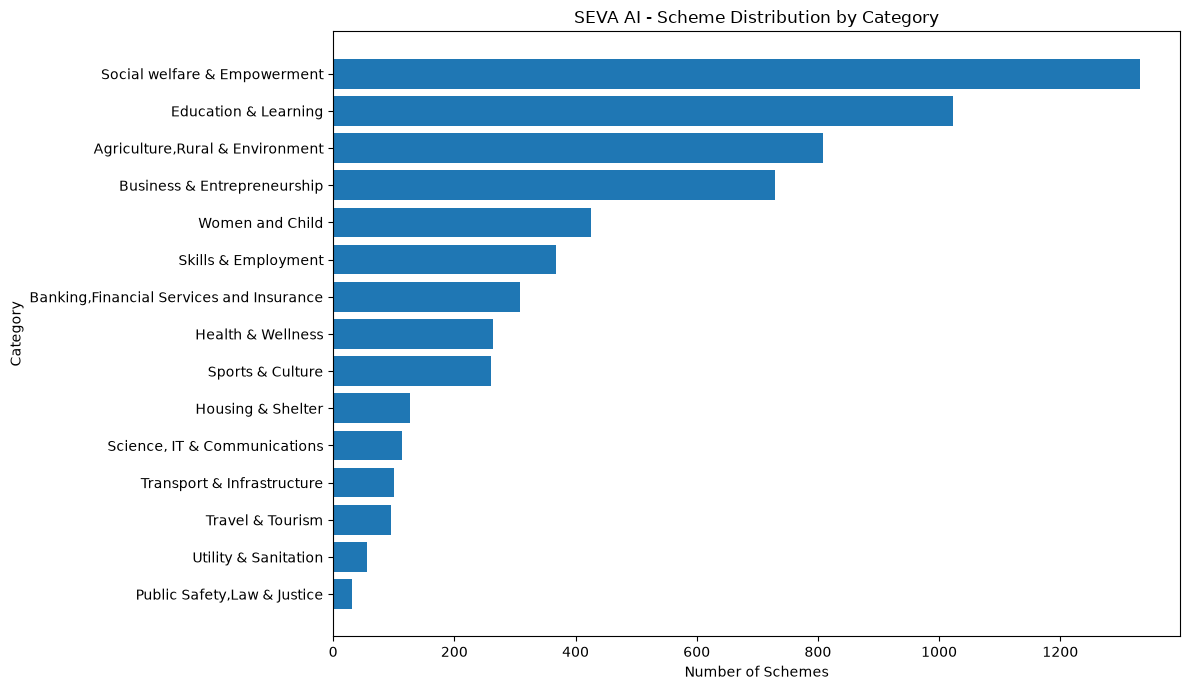

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    category_df["category"],
    category_df["total_schemes"]
)

plt.xlabel("Number of Schemes")
plt.ylabel("Category")
plt.title("SEVA AI - Scheme Distribution by Category")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [27]:
scheme_category_count = {}

for scheme in schemes:

    scheme_id = str(
        scheme.get("scheme_id", "")
    ).strip()

    if not scheme_id:
        continue

    categories = scheme.get("categories", [])

    if isinstance(categories, str):
        categories = [categories]

    categories = set(
        str(category).strip()
        for category in categories
        if str(category).strip()
    )

    scheme_category_count[scheme_id] = len(categories)


overlap_df = pd.Series(
    scheme_category_count.values()
).value_counts().sort_index()

overlap_df = overlap_df.rename_axis(
    "number_of_categories"
).reset_index(name="number_of_schemes")

overlap_df

,number_of_categories,number_of_schemes
0,1,3037
1,2,1198
2,3,171
3,4,18
4,5,1
5,6,3


In [29]:
# Save category-wise scheme IDs

category_mapping = {
    category: ids
    for category, ids in category_scheme_ids.items()
}

with open(
    "G:\\SEVA_Ai\\SEVA_Ai\\notebooks\\output\\category_scheme_ids.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        category_mapping,
        file,
        indent=4,
        ensure_ascii=False
    )


# Save category summary

category_df.to_csv(
    "G:\\SEVA_Ai\\SEVA_Ai\\notebooks\\output\\category_summary.csv",
    index=False
)


# Save category summary as JSON

category_df.to_json(
    "G:\\SEVA_Ai\\SEVA_Ai\\notebooks\\output\\category_summary.json",
    orient="records",
    indent=4,
    force_ascii=False
)


print("Category analysis saved successfully!")

Category analysis saved successfully!
